<a href="https://colab.research.google.com/github/100522401/P1_AA_100522396_100522401/blob/main/notebooks/Cuaderno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practica 1 NIA 100522396 NIA 100522401


# Introducción



El objetivo de la práctica es **construir un modelo** de aprendizaje automático capaz de predecir si un cliente bancario suscribirá un depósito a plazo. Para construir ese modelo nos basaremos en la información demográfica, financiera e interacciones de los clientes.

Como variable objetivo del problema tenemos 'deposit'. Esta variable indicará si el cliente contrató, o no, el producto ofrecido. Por tanto, se trata de un problema de **clasificación binaria**.
<br><br>
En este cuaderno se incluye:

  - Exploratory Data Analysis (EDA).
  - Definir una estrategia de evaluación.
  - Optimización de hiperparámetros (HPO).
  - Selección del mejor modelo y estudio de su rendimiento.
  - Entrenamiento del modelo final.

## Configuración inicial y carga de datos

En esta sección se importan las librerías básicas usadas, se fija la semilla con el nía 1005224**01** y se cargan los datos desde Google Drive

En primer lugar, se importan las librerías básicas y fijamos la semilla aleatoria.

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 100522401
np.random.seed(SEED)


Cargamos el dataset de entrenamiento desde Google Drive

In [146]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/P1_AA_datasets"
TRAIN_PATH = f"{BASE_DIR}/bank_01.pkl"
# COMP_PATH  = f"{BASE_DIR}/bank_competition.pkl"

print("TRAIN_PATH:", TRAIN_PATH)
# print("COMP_PATH:", COMP_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TRAIN_PATH: /content/drive/MyDrive/P1_AA_datasets/bank_01.pkl


Se comprueba que el dataset se ha cargado correctamente

In [147]:
#TODO: Se podrían añadir try/excepts al read...

data = pd.read_pickle(TRAIN_PATH)
display(data.head())
print("\nDatos cargados correctamente.")

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes



Datos cargados correctamente.


# EDA

En esta sección se realiza un análisis exploratorio de los datos (EDA) básico.

En este estudio determinaremos:

- Número de instancias.
- Número de variables ( incluyendo la variable objetivo).
- Identificación de variables numéricas, categóricas u ordinales.
- Estudio de cardinalidad.
- Análisis de la variable 'pdays'.
- Estudio de los valores faltantes, constantes o identificadores.
- Estudio del problema y análisis de desbalanceos de la variable objetivo.


En este bloque se calcula el tamaño del dataset (número de instancias y variables). También se verfiica que la variable objetivo existe. Se comprueba cuántos valores únicos tienen deposit para confirmar el tipo de problema.

In [148]:
#Tamaño del dataset y tipo de problema
n_rows, n_cols = data.shape
print(f"Instancias: {n_rows}")
print(f"Variables totales (incluyendo target): {n_cols}")

target = "deposit"
if target not in data.columns:
    raise ValueError(f"No existe la variable objetivo '{target}' en el dataset.")

n_unique_target = data[target].nunique(dropna=False)
print(f"Variable objetivo: {target}")
print(f"Valores únicos en target: {n_unique_target}")

# La variable 'deposit' indica si suscribe o no: problema de clasificación binaria.
if n_unique_target == 2:
    problem_type = "clasificación binaria"
else:
    problem_type = "clasificación (revisar codificación de clases)"

print(f"Tipo de problema: {problem_type}")

Instancias: 11000
Variables totales (incluyendo target): 17
Variable objetivo: deposit
Valores únicos en target: 2
Tipo de problema: clasificación binaria


En este caso tenemos dos clases, y por lo tanto se concluye que es un problema de **clasificación binaria** (se suscribe o no se suscribe). Es importante tener esto en cuenta ya que condiciona la elección de modelos y métricas en el resto de la práctica.

En este bloque se identifican los tipos de variables, separandolas en numéricas (donde se incluyen als booleanas) y categóricas. Esta distinción nos ayudará a definir el preprocesado, ya que las variables numéricas y categóricas requieren transformaciones distintas.

In [149]:
# 2) Tipos de variables
X = data.drop(columns=[target])

num_cols = X.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Numéricas: {len(num_cols)}")
print(num_cols)
print("\nCategóricas: {0}".format(len(cat_cols)))
print(cat_cols)

Numéricas: 7
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categóricas: 9
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


Se han identificado 7 variables numéricas y 9 varaibels catagóricas. Esta separación nos sirve para contruir las pipelines de preprocesado, aplicando transformaciones especificas a cada tipo de variable.

Ahora calcularemos la cardinalidad (número de valores únicos) de las variables categóricas para detectar posibles casos de alta cardinalidad. Es importante tenerlo en cuenta porque al aumentar la dimensionalidad del conjunto de datos, aumenta el coste computacional y el rendimiento del modelo.

In [150]:
# 3) Cardinalidad en variables categóricas
if len(cat_cols) == 0:
    print("No hay variables categóricas.")
else:
    cardinality = X[cat_cols].nunique(dropna=False).sort_values(ascending=False)
    display(cardinality.to_frame("n_unique"))

    high_card_cols = cardinality[cardinality > 10].index.tolist()
    if high_card_cols:
      print("\nCategóricas con alta cardinalidad (>10):", high_card_cols)
    else:
      print("\nCategóricas con alta cardinalidad (>10): ninguna")

,n_unique
job,13
month,12
education,5
poutcome,4
marital,3
contact,3
default,2
housing,2
loan,2



Categóricas con alta cardinalidad (>10): ['job', 'month']


En este caso, se observa que hay dos columnas que superan el umbral de alta caridnalidad (> 10 valores únicos).

A continuación analizaremos los valores faltantes del dataset, calculando para cada variable cuántos valores nulos aparecen y qué porcentaje representan. Esta información es importante para decidir quÉ estrategia se utilizará en el preprocesado (imputación)

In [151]:
# 4) Valores faltantes
missing_count = data.isna().sum().sort_values(ascending=False)
missing_ratio = (missing_count / len(data) * 100).round(2)
missing_df = pd.DataFrame({"n_missing": missing_count, "pct_missing": missing_ratio})
missing_df = missing_df[missing_df["n_missing"] > 0]

if missing_df.empty:
    print("No hay valores faltantes.")
else:
    display(missing_df)


,n_missing,pct_missing
education,316,2.87
job,169,1.54


Se observa que hay dos varibales con valores faltantes. Estas variables requerirán una estrategia de imputación en el preprocesado, que constará en el pipeline. Esto evitará problemas durante el entrenamiento de los modelos.

Se buscan posibles comunas problemáticas para el modelado: columnas constantes y columnas tipo ID (con valores casi únicos o identificables). ESte tipo de variables aporta poca capacidad predicitiva y puede introducir ruido o sobreajusnte, por lo que es mejor detectarlas antes del preprocesado.

In [152]:
# 5) Columnas constantes y posibles ID
nunique = X.nunique(dropna=False)
constant_cols = nunique[nunique <= 1].index.tolist()

id_like_by_name = [c for c in X.columns if "id" in c.lower()]
id_like_by_uniqueness = [c for c in X.columns if X[c].nunique(dropna=False) >= 0.98 * len(X)]
id_like_cols = sorted(set(id_like_by_name + id_like_by_uniqueness))

print("Columnas constantes:", constant_cols if constant_cols else "ninguna")
print("Posibles columnas ID:", id_like_cols if id_like_cols else "ninguna")

Columnas constantes: ninguna
Posibles columnas ID: ninguna


No se han detectado **columnos constantes** ni **posibles columnas tipo ID** en el dataset. Por tanto, no es necesario eliminar variables por estos motivos en el preprocesao y modelado.

Ahora analizaremos la distribución de la variable objetivo **deposit**, ya que en problemas de clasificación el desbalanceo relevante relamente es el de las clases que se buscan predecir. ESta información nos será útil para justificar la elección de la métrica y la comparación entre modelos.

En este bloque se analiza la variable **pdays**, la cual representa el númerod e dúas desde el último contacto en la campaña anterior y tomará el valor **-1** cuando el cliente no ha sido contactado previamente. ENtonces, calcularemos la proporcion de valores -1 y se describen los valores válidos (pdays!=-1) para decidir como tratar la variable en el preprocesado.

Conteo por clase:
deposit
no     5780
yes    5220
Name: count, dtype: int64

Porcentajes (%):
deposit
no     52.55
yes    47.45
Name: proportion, dtype: float64

Imbalance ratio (mayor/minor): 1.11


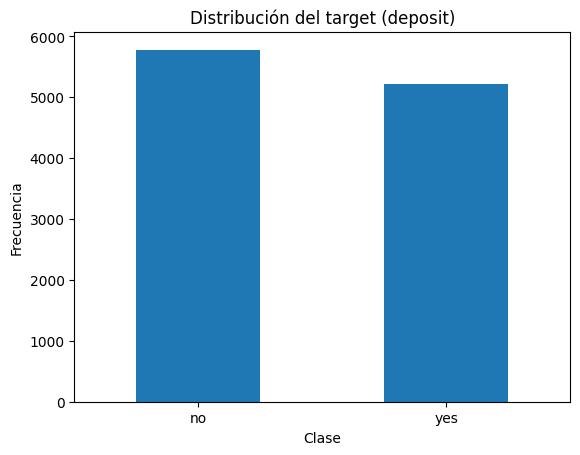

In [153]:
# Desbalanceo del target

counts = data[target].value_counts(dropna=False)
perc = data[target].value_counts(normalize=True, dropna=False) * 100

# Conteo y porcentaje por clase
print("Conteo por clase:")
print(counts)

print("\nPorcentajes (%):")
print(perc.round(2))

# Ratio de desbalanceo (mayor/minor)
imbalance_ratio = counts.max() / counts.min()
print("\nImbalance ratio (mayor/minor):", round(imbalance_ratio, 2))

# Gráfico
ax = counts.plot(kind="bar")
plt.title("Distribución del target (deposit)")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.xticks(rotation=0)
plt.show()

La variable objetivo presenta una distribución de 52,55% para la clase no y 47,45% para la clase yes. Por tanto, el problema puedoe considerarse prácticamente equilibrado, con un desbalanceo poco notorio.

In [154]:
# Analisis de pdays
p = data["pdays"]

n_total = len(p)
n_minus1 = (p == -1).sum()
pct_minus1 = 100 * n_minus1 / n_total

print(f"Total: {n_total}")
print(f"pdays = -1 (sin contacto previo): {n_minus1} ({pct_minus1:.2f}%)")

p_valid = p[p != -1]
print("\nResumen pdays (solo contactos previos reales):")
n_notminus1 = (p != -1).sum()
pct_notminus1 = 100 * n_notminus1 / n_total
print(f"pdays != -1 (solo contactos previos reales): {n_notminus1} ({pct_notminus1:.2f}%)")

display(p_valid.describe())



Total: 11000
pdays = -1 (sin contacto previo): 8203 (74.57%)

Resumen pdays (solo contactos previos reales):
pdays != -1 (solo contactos previos reales): 2797 (25.43%)


,pdays
count,2797.000000
mean,204.718627
std,122.397953
min,1.000000
25%,98.000000
50%,182.000000
75%,286.000000
max,854.000000


Se observa que **pdays == -1** aparece en **8203 de 11000 instancias (74.57%)**, lo que indica que en al mayoría de los casos no existe un contacto previo. Por tanto, el valor -1 no debe interpretarse como un valor numérico, ya que no aporta informaciónr relevante al modelado. Para los casos de **pdays != -1**, el número de días tiene una distribución amplia ( mediana **182**, rango **1 - 854**), lo que aporta información que puede ser útil para el modelado.

En este bloque se dine el preprocesado de **pdays**. DAdo que **pdays == -1** no represnta un número de días real, sino "sin contacto previo", separemos esta información en una **variable binaria (contacted_before)** y se trasnforma pdays para que contenga únicamente valores numéricos válidos, reemplazando -1 por NaN. De este modo se evita que -1 distorsione el escalado de la variable.

In [155]:
# Preprocesado pdays


# Creo nueva columna 0: no contactado previamente 1: contactado previamente
data['contacted_before'] = (data['pdays'] != -1).astype(int)

# Remplazo -1 de pdays por Nan
data["pdays"] = data["pdays"].replace(-1, np.nan)

data.head(300)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit,contacted_before
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,NaN,0,unknown,yes,0
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,NaN,0,unknown,yes,0
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,NaN,0,unknown,yes,0
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,NaN,0,unknown,yes,0
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,NaN,0,unknown,yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300,36,blue-collar,divorced,secondary,no,638,yes,no,unknown,16,jun,1395,2,NaN,0,unknown,yes,0
301,48,unemployed,single,tertiary,no,3229,no,no,unknown,16,jun,1089,1,NaN,0,unknown,yes,0
302,51,management,single,secondary,no,1610,yes,no,unknown,16,jun,1248,3,NaN,0,unknown,yes,0
303,51,blue-collar,married,secondary,no,33,no,yes,unknown,16,jun,721,3,NaN,0,unknown,yes,0


## 3. Esquema de evaluación

In [156]:
from sklearn.model_selection import train_test_split, StratifiedKFold

#Todas las columnas menos la target
X = data.drop(columns='deposit')
#Solo columna target
y = data['deposit']

# Recalculamos listas de columnas numéricas y categóricas
num_cols = X.select_dtypes(include=['number', 'bool']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Variables numéricas ({len(num_cols)}): {num_cols}")
print(f"Variables categóricas ({len(cat_cols)}): {cat_cols}\n")

# Hacemos particiones
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=1/3,
    stratify=y,
    random_state=SEED
)

print("Tamaño de X_train:", X_train.shape)
print("Tamaño de X_test:", X_test.shape)

# Se define la validación cruzada (3-fold)
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

print('\n')
print(cv_inner)

Variables numéricas (8): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'contacted_before']
Variables categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Tamaño de X_train: (7333, 17)
Tamaño de X_test: (3667, 17)


StratifiedKFold(n_splits=3, random_state=100522401, shuffle=True)


Se utilizará el F1-score como métrica principal de evaluación, ya que se trata de un problema de clasificación binaria y nos interesa medir de forma equilibrada la capacidad del modelo para identificar correctamente la clase positiva. Aunque el desbalanceo no es muy significativo, la accuracy puede ser menos representativa, mientras que el F1-score combina precisión y recall en una única medida y permite comparar mejor el rendimiento de los distintos modelos.

# 4. Pipeline de preprocesado

En esta sección se construye el pipeline de preprocesado que se aplicará a los datos antes de entrenar cada modelo. El pipeline se encargará de:
  1. **Variables numéricas**: Se tratarán los valores faltantes mediante imputación con la mediana. También, en caso de ser necesario, se usará escalado de las variables.

  2. **Variables categórcas**: Se tratarán los valores faltantes con la categoría más frecuente o moda. A continuación se codificará mediante One-Hot Encoding

In [157]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder


def build_preprocessor(num_cols, cat_cols, numeric_scaler=None):
    """Construye el preprocesado para variables numericas y categoricas."""

    # Pipeline para las variables numéricas: imputar NaN con mediana + scaler
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if numeric_scaler is not None:
        numeric_steps.append(("scaler", numeric_scaler))
    numerical_pipeline = Pipeline(numeric_steps)

    # Pipeline para categóricas: imputar NaN con moda + OneHotEncoder
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    # ColumnTransformer: Se aplican las transformaciones según el tipo de variable
    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ])

    return preprocessor


def create_pipeline(model, num_cols, cat_cols, numeric_scaler=None):
    """Une el preprocesado y el modelo final en una sola pipeline."""
    preprocessor = build_preprocessor(num_cols, cat_cols, numeric_scaler=numeric_scaler)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])


print("Pipeline base de preprocesado definida correctamente.")


Pipeline base de preprocesado definida correctamente.


## 4.1 Seleccion del mejor scaler para KNN

En esta sección compararemos los diferentes scalers propuestos para quedarnos con el mejor, primero comparamos **StandardScaler**, **MinMaxScaler** y **RobustScaler** usando **KNN con hiperparametros por defecto**.

Esta comparacion se hace solo sobre `X_train` mediante la evaluacion inner (`StratifiedKFold` de 3 particiones).

Para evaluar el rendimiento de cada scaler, se utiliza el **F1-score** como métrica principal. Se ha escogido esta métrica a pesar que el problema este relativamente equilibrado ya que esta métrica mide el equilibrio entre **precision** y **recall**.

Además, para completar el análisas se estudian otras métricas:

- **ROC AUC**: resulta útil como métrica complemetaria ya que mide la capacidad del modelo para separar las distintas clases.
- **Accuracy**: al tratarswe de un problema relativamente equilibrado, aporta información que puede ser útil sobre el porcentaje de aciertos del modelo.
- **Precision**
- **Recall**

De esta manera, el **F1-score** se toma como criterio principal para comparar los scalers, mientras que **accuracy, precision, recall** y **ROC AUC** se emplean com métricas complementarias.


In [158]:
import time
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import make_scorer, f1_score, precision_score, recall_score

# Se definen las métricas para evaluar los scalers
SCORING = {
    "f1": make_scorer(f1_score, pos_label="yes"),
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="yes"),
    "recall": make_scorer(recall_score, pos_label="yes"),
    "roc_auc": "roc_auc"
}

# Se definen los scalers a comparar
scalers = {
    "standard": StandardScaler(),
    "minmax": MinMaxScaler(),
    "robust": RobustScaler(),
}

# Lista donde se almacenarán los resultados
scaler_results = []

# Se extraen las num_cols y cat_cols del train (evitar data leakeage)
num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# 3-fold crossvalidation scalers
for scaler_name, scaler in scalers.items():
  # Se crea la pipeline con KNN y scaler actual
    knn_pipe = create_pipeline(
        KNeighborsClassifier(),
        num_cols=num_cols_train,
        cat_cols=cat_cols_train,
        numeric_scaler=scaler
    )

    start = time.perf_counter()

    cv_out = cross_validate(
        knn_pipe,
        X_train,
        y_train,
        cv=cv_inner,
        scoring = SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )
    elapsed = time.perf_counter() - start

    # Se guardan las medias y desviaciones de las métricas
    scaler_results.append({
        "scaler": scaler_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),  # Desviación estándar f1-score
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })

# Se muestran los resultados
scaler_results_df = pd.DataFrame(scaler_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(scaler_results_df)

best_scaler_name = scaler_results_df.loc[0, "scaler"]
best_scaler = scalers[best_scaler_name]
print(f"\nMejor scaler para KNN según F1 medio: {best_scaler_name}")

,scaler,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,standard,0.775376,0.011051,0.795174,0.808546,0.744828,0.863080,0.157852,0.867034,5.092422
1,robust,0.745040,0.020404,0.766538,0.773423,0.718678,0.838882,0.165557,0.747437,1.744696
2,minmax,0.690235,0.010215,0.729579,0.756442,0.634770,0.789718,0.118124,0.854376,1.815174



Mejor scaler para KNN según F1 medio: standard


De esta comparación se puede concluir que **StandardScaler** es el scaler que ofrece el mejor rendimiento para KNN, ya que obtiene los valores más altos en todas las métricas evaluadas.

Se observa también que **RobustScaler** ocupa una posición intermedia, con un rendimiento inferior al de StandardScaler pero superior al de MinMaxScaler. Por último, **MinMaxScaler** es el scaler que presenta los peores resultados.

Consecuentemente y a partir de este punto, el scaler seleccionado será **StandardScaler**, y por tanto, se empleará cuando el modelo necesite ser escalado.


## Evaluación de KNN con hiperparámetros por defecto

En esta sección se evalúa un modelo **KNN** con sus hiperparámetros por defecto, utilizando el método de escalado ya seleccionado(**StandardScaler**). EL objetivo es obtener una referencia inicial del rendimiento antes de realizar la HPO.

Además se medirá el tiempo de entrenamiento, ya que el coste computacional tendrá también peso en la comparación.

In [159]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

# Inner crossvalidation
cv_inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Pipeline
pipeline_knn_default = create_pipeline(
    model=KNeighborsClassifier(),
    num_cols=num_cols_train,
    cat_cols=cat_cols_train,
    numeric_scaler=StandardScaler()
)

# Tiempo
start = time.perf_counter()

scores_knn_default = cross_validate(
    pipeline_knn_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
  )

elapsed = time.perf_counter() - start

print("KNN con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_knn_default['test_f1'].mean():.4f} ± {scores_knn_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_knn_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_knn_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_knn_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_knn_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_knn_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

KNN con hiperparámetros por defecto:

F1 medio: 0.7754 ± 0.0111

Accuracy medio: 0.7952
Precision media: 0.8085
Recall medio: 0.7448
ROC-AUC medio: 0.8631
Tiempo medio de fit: 0.1519 s
Tiempo total CV: 1.8167 s


##DummyClassifier
// este apartado luego lo movemos al final para las conclusiones

En esta sección se evalúan dos clasificadores **Dummy** para medir el rendimiento de clasificadores **triviales**. Un **DummyClassifier** no aprende patrones reales de los atributos, simplemente predice según una regla muy básica, por ejemplo escoger siempre la clase mayoritaria o generar predicciones aleatorias respetando la distribución de clases.

Esto sirve como base. Si **KNN** o los **árboles** no mejoran claramente a un **dummy**, entonces el modelo no estaría aprendiendo información útil del problema.

In [160]:
from sklearn.dummy import DummyClassifier

# Se definen los clasificadores dummy a comparar
dummy_models = {
    "most_frequent": DummyClassifier(strategy="most_frequent"),
    "stratified": DummyClassifier(strategy="stratified", random_state=SEED),
}

# Lista donde se guardan los resultados
dummy_results = []

# Evaluación de cada dummy con validación cruzada
for dummy_name, dummy_model in dummy_models.items():
    start = time.perf_counter()

    cv_out = cross_validate(
        dummy_model,
        X_train,
        y_train,
        cv=cv_inner,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=False,
        error_score="raise"
    )

    elapsed = time.perf_counter() - start

    # Se guardan las medias de las métricas y los tiempos
    dummy_results.append({
        "modelo": dummy_name,
        "f1_mean": cv_out["test_f1"].mean(),
        "f1_std": cv_out["test_f1"].std(),
        "accuracy_mean": cv_out["test_accuracy"].mean(),
        "precision_mean": cv_out["test_precision"].mean(),
        "recall_mean": cv_out["test_recall"].mean(),
        "roc_auc_mean": cv_out["test_roc_auc"].mean(),
        "fit_time_mean": cv_out["fit_time"].mean(),
        "score_time_mean": cv_out["score_time"].mean(),
        "total_cv_time": elapsed
    })

# Se muestran los resultados ordenados por F1 medio
dummy_results_df = pd.DataFrame(dummy_results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(dummy_results_df)

,modelo,f1_mean,f1_std,accuracy_mean,precision_mean,recall_mean,roc_auc_mean,fit_time_mean,score_time_mean,total_cv_time
0,stratified,0.476707,0.00418,0.500613,0.474132,0.47931,0.499582,0.016881,0.130978,0.309208
1,most_frequent,0.000000,0.00000,0.525433,0.000000,0.00000,0.500000,0.015599,0.100903,0.260989


## Evaluación de árboles con hiperparámetros por defecto

A continuación se evalúa un **DecisionTreeClassifier** con sus hiperparámetros por defecto. En este caso, a diferencia de KNN, no es necesario aplicar escalado a las variables numéricas, ya que los árboles no dependen de distancias entre observaciones.

In [161]:
from sklearn.tree import DecisionTreeClassifier

# Se extraen las columnas numéricas y categóricas del train
num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Pipeline del árbol con hiperparámetros por defecto
pipeline_tree_default = create_pipeline(
    model=DecisionTreeClassifier(random_state=SEED),
    num_cols=num_cols_train,
    cat_cols=cat_cols_train,
    numeric_scaler=None
)

# Tiempo de la validación cruzada
start = time.perf_counter()

scores_tree_default = cross_validate(
    pipeline_tree_default,
    X_train,
    y_train,
    cv=cv_inner,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise"
)

elapsed = time.perf_counter() - start

print("Árbol con hiperparámetros por defecto:\n")
print(f"F1 medio: {scores_tree_default['test_f1'].mean():.4f} ± {scores_tree_default['test_f1'].std():.4f}")
print(f"\nAccuracy medio: {scores_tree_default['test_accuracy'].mean():.4f}")
print(f"Precision media: {scores_tree_default['test_precision'].mean():.4f}")
print(f"Recall medio: {scores_tree_default['test_recall'].mean():.4f}")
print(f"ROC-AUC medio: {scores_tree_default['test_roc_auc'].mean():.4f}")
print(f"Tiempo medio de fit: {scores_tree_default['fit_time'].mean():.4f} s")
print(f"Tiempo total CV: {elapsed:.4f} s")

Árbol con hiperparámetros por defecto:

F1 medio: 0.7734 ± 0.0151

Accuracy medio: 0.7866
Precision media: 0.7795
Recall medio: 0.7675
ROC-AUC medio: 0.7857
Tiempo medio de fit: 0.1670 s
Tiempo total CV: 0.5744 s


## Árbol poco profundo

Además del árbol con hiperparámetros por defecto, utilizamos un árbol **poco profundo** para obtener una interpretación de cómo podrían tomarse decisiones en este problema. Para ello se entrenará un árbol con profundidad reducida, lo que facilita visualizar las reglas principales de decisión.

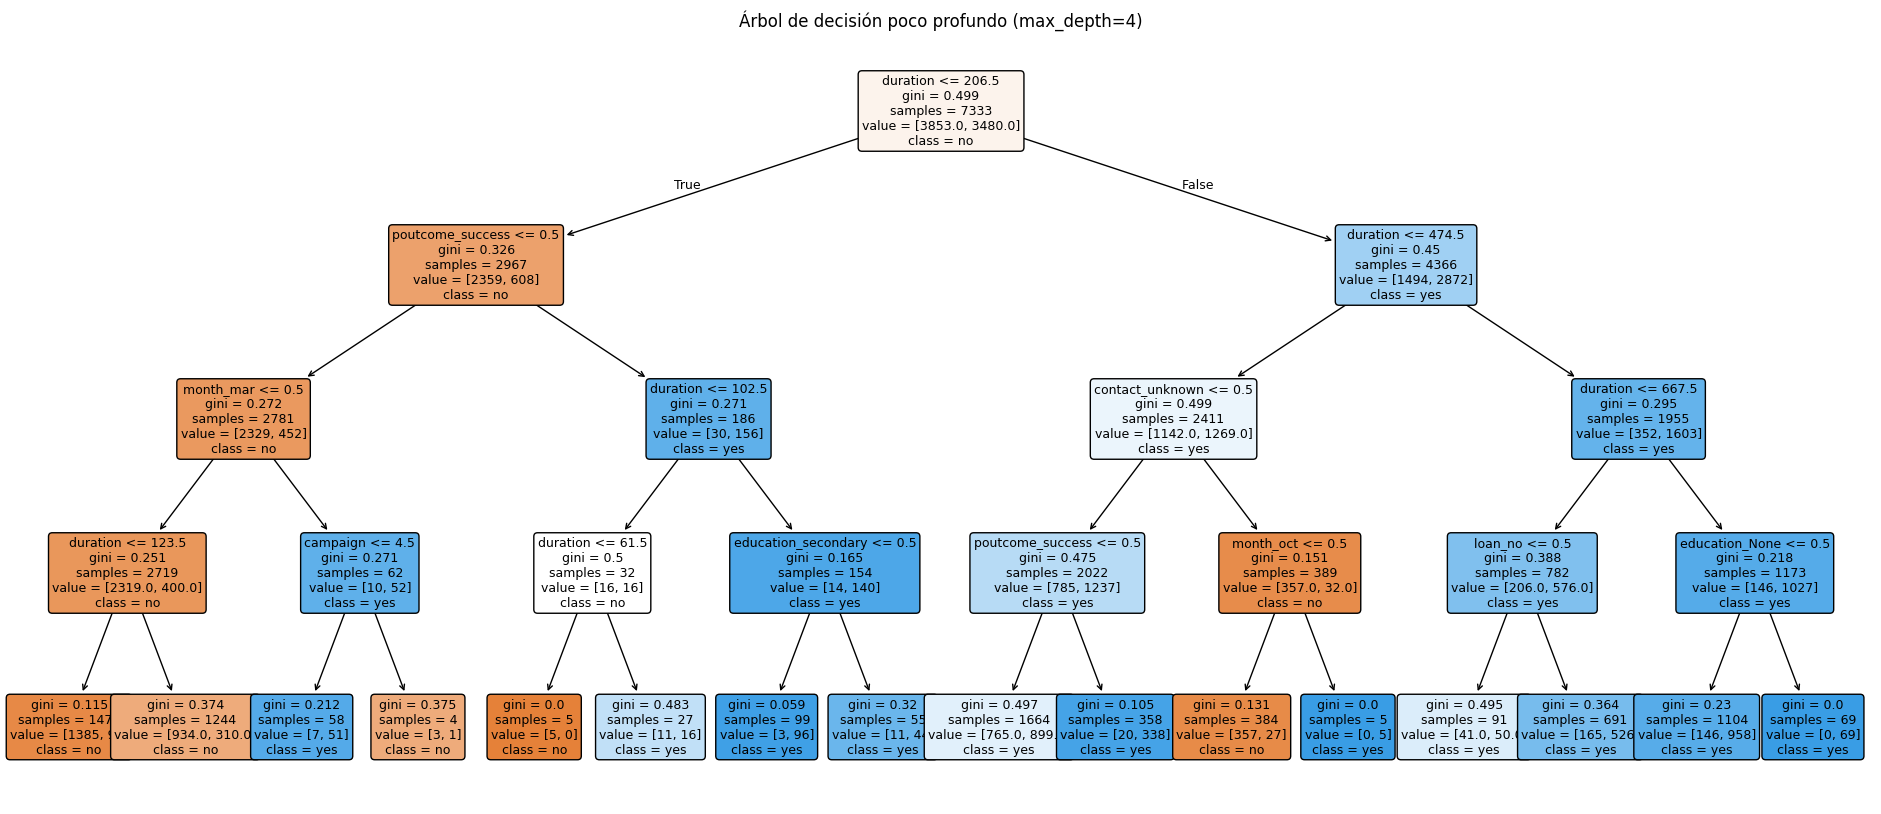

In [162]:
from sklearn.tree import plot_tree

# Se extraen las columnas numéricas y categóricas del train
num_cols_train = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols_train = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Pipeline del árbol poco profundo
pipeline_tree_shallow = create_pipeline(
    model=DecisionTreeClassifier(max_depth=4, random_state=SEED),
    num_cols=num_cols_train,
    cat_cols=cat_cols_train,
    numeric_scaler=None
)

# Se ajusta el modelo para poder visualizarlo
pipeline_tree_shallow.fit(X_train, y_train)

# Se recuperan los nombres de las variables tras el preprocesado
preprocessor_fitted = pipeline_tree_shallow.named_steps["preprocessor"]
cat_feature_names = preprocessor_fitted.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols_train)
feature_names = num_cols_train + list(cat_feature_names)

# Representación gráfica del árbol
plt.figure(figsize=(24, 10))
plot_tree(
    pipeline_tree_shallow.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["no", "yes"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Árbol de decisión poco profundo (max_depth=4)")
plt.show()
